# Saffron Adulteration Detection with Transfer Learning

**Integrating Machine Learning for Enhanced Saffron Cultivation: Adulteration Detection**
*Rebuilt from an IIT Kharagpur B.Tech thesis (Agricultural and Food Engineering) as a reproducible, production-grade pipeline.*

---

## 1. Introduction

Saffron is the most expensive spice by weight, which makes it one of the most frequently adulterated. Common frauds include passing off dried saffron stems, stems dyed with food coloring, or fully synthetic threads as genuine stigma. Consumers also distrust genuine saffron simply because the two legitimate drying methods (dryer vs. pressing) produce visibly different colors.

This notebook classifies saffron images into five classes:

| Class | Group | Description |
|---|---|---|
| **C1** | Pure | Saffron stigma dried with a dryer |
| **C2** | Pure | Saffron stigma dried by pressing |
| **C3** | Counterfeit | Dried saffron stem |
| **C4** | Counterfeit | Saffron stem colored with food dye |
| **C5** | Counterfeit | Synthetic / artificial saffron |

**Baseline.** The original thesis used a small custom CNN trained from scratch (two conv blocks, 256 px input, batch size 8). It reached roughly **70.8% validation accuracy**, with the weakest performance on **C5 (F1 0.50)** and frequent confusion between **C4 and C5**.

**What this notebook does differently.**

1. **Transfer learning** from ImageNet with three strong backbones (EfficientNetB3, ResNet50V2, DenseNet121), trained in two phases: frozen feature extraction, then partial fine-tuning.
2. **Lightweight hyperparameter search** (learning rate, batch size, dropout) per backbone.
3. **Automatic model selection** on validation macro-F1, with a held-out test set touched only once, by the final model.
4. **Publication-quality evaluation** (confusion matrix, ROC, PR, per-class F1 against the thesis baseline) and **Grad-CAM** explanations.
5. **Deployment-ready export.** Preprocessing is built into the model graph, so a web client only has to send raw RGB pixels.

> **How to run:** `Runtime → Change runtime type → GPU (T4 or better)`, then `Runtime → Run all`. Expected runtime on a T4 is roughly 30 to 50 minutes for the full three-backbone comparison.

### 1.1 Environment setup

Colab ships with TensorFlow/Keras 3 preinstalled, so TensorFlow is **not** reinstalled here (reinstalling it is the most common way to break a Colab runtime). Only Albumentations is upgraded to the 2.x API used below.

In [1]:
!pip install -q -U "albumentations>=2.0.5"

In [2]:
import os, sys, gc, json, math, time, random, shutil, hashlib, itertools, warnings
from pathlib import Path
from collections import Counter
from datetime import datetime, timezone

import numpy as np
import pandas as pd
import cv2
from PIL import Image, ImageOps

import tensorflow as tf
import keras
import albumentations as A

import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (accuracy_score, f1_score, log_loss, classification_report,
                             confusion_matrix, roc_curve, auc, roc_auc_score,
                             precision_recall_curve, average_precision_score)
from sklearn.preprocessing import label_binarize

warnings.filterwarnings("ignore", category=UserWarning)
cv2.setNumThreads(0)  # avoid thread oversubscription inside the augmentation workers

def _version_tuple(v):
    return tuple(int("".join(ch for ch in p if ch.isdigit()) or 0) for p in v.split(".")[:2])

print(f"Python        : {sys.version.split()[0]}")
print(f"TensorFlow    : {tf.__version__}")
print(f"Keras         : {keras.__version__}")
print(f"Albumentations: {A.__version__}")
print(f"OpenCV        : {cv2.__version__}")

if _version_tuple(tf.__version__) < (2, 18):
    print("WARNING: this notebook targets TensorFlow 2.18+. Some APIs may behave differently.")
assert _version_tuple(keras.__version__) >= (3, 0), "Keras 3 is required (bundled with TF >= 2.16)."

Python        : 3.13.15
TensorFlow    : 2.20.0
Keras         : 3.13.2
Albumentations: 2.0.8
OpenCV        : 5.0.0


### 1.2 Mount Google Drive

In [3]:
try:
    from google.colab import drive
    drive.mount("/content/drive")
    IN_COLAB = True
except ImportError:
    IN_COLAB = False
    print("Not running in Colab; make sure DATA_DIR below points to your local dataset.")

Mounted at /content/drive


### 1.3 Configuration

Every tunable setting lives in this one cell. Defaults are chosen for a ~500-image dataset on a Colab T4.

In [4]:
# ----------------------------- Paths -----------------------------
DATA_DIR         = Path("/content/drive/MyDrive/data")          # expects data/C1 ... data/C5
PROJECT_DIR      = Path("/content/saffron_project")             # local working directory
DRIVE_EXPORT_DIR = Path("/content/drive/MyDrive/saffron_adulteration_artifacts")  # persisted copy

MODELS_DIR  = PROJECT_DIR / "models"
OUTPUTS_DIR = PROJECT_DIR / "outputs"
GRADCAM_DIR = OUTPUTS_DIR / "gradcam"
CKPT_DIR    = PROJECT_DIR / "checkpoints"                       # temporary, deleted at the end
for d in (MODELS_DIR, OUTPUTS_DIR, GRADCAM_DIR, CKPT_DIR):
    d.mkdir(parents=True, exist_ok=True)

# --------------------------- Data -------------------------------
SEED           = 42
IMG_SIZE       = 300                       # model input (EfficientNetB3 native resolution)
LOAD_SIZE      = int(round(IMG_SIZE * 1.15))  # slightly larger cache so random crops keep detail
VAL_FRACTION   = 0.15
TEST_FRACTION  = 0.15
VALID_EXTS     = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff", ".webp"}
MIN_SIDE_PX    = 32
IMBALANCE_TOL  = 1.2                       # use class weights only if max/min class count exceeds this

# --------------------------- Models -----------------------------
BACKBONES        = ["EfficientNetB3", "ResNet50V2", "DenseNet121"]
IMAGENET_WEIGHTS = "imagenet"

# ------------------ Hyperparameter search space ------------------
SEARCH_SPACE = {
    "learning_rate": [1e-3, 5e-4],
    "batch_size":    [16, 32],
    "dropout":       [0.2, 0.4],
}
N_TRIALS    = 4        # configs sampled from the grid (same configs for every backbone)
TUNE_EPOCHS = 8        # frozen-backbone epochs per trial

# ---------------------------- Training ---------------------------
HEAD_EPOCHS         = 15     # phase 1: frozen backbone
FINETUNE_EPOCHS     = 35     # phase 2: top of backbone unfrozen
FINETUNE_FRACTION   = 0.30   # fraction of backbone layers (from the top) to unfreeze
FINETUNE_LR_FACTOR  = 0.10   # phase-2 LR = best LR * factor
WEIGHT_DECAY        = 1e-4
LABEL_SMOOTHING     = 0.10
EARLY_STOP_PATIENCE = 8
PLATEAU_PATIENCE    = 3
PLATEAU_FACTOR      = 0.5
MIN_LR              = 1e-7
WARMUP_EPOCHS       = 1
WORKERS             = 4      # parallel augmentation threads

# -------------------------- Explainability ------------------------
N_GRADCAM = 12

# Human-readable labels (used in figures and exported metadata when folder names match)
CLASS_DESCRIPTIONS = {
    "C1": "Pure saffron (dryer)",
    "C2": "Pure saffron (pressed)",
    "C3": "Dried saffron stem",
    "C4": "Colored saffron stem",
    "C5": "Artificial saffron",
}
# Per-class test F1 of the original thesis CNN (for the comparison figure)
THESIS_BASELINE = {
    "val_accuracy": 0.7083,
    "per_class_f1": {"C1": 0.8000, "C2": 0.6667, "C3": 0.9677, "C4": 0.7500, "C5": 0.5000},
}

In [5]:
# ---------------------- Reproducibility & hardware ----------------------
os.environ["PYTHONHASHSEED"] = str(SEED)
keras.utils.set_random_seed(SEED)   # seeds Python, NumPy and TensorFlow

gpus = tf.config.list_physical_devices("GPU")
for g in gpus:
    try:
        tf.config.experimental.set_memory_growth(g, True)
    except RuntimeError:
        pass

USE_MIXED_PRECISION = len(gpus) > 0
if USE_MIXED_PRECISION:
    keras.mixed_precision.set_global_policy("mixed_float16")
    gpu_name = tf.config.experimental.get_device_details(gpus[0]).get("device_name", "GPU")
    print(f"GPU detected: {gpu_name}  ->  mixed precision ON (mixed_float16)")
else:
    gpu_name = "none"
    keras.mixed_precision.set_global_policy("float32")
    print("WARNING: no GPU detected. Training will run on CPU and be very slow.\n"
          "In Colab: Runtime -> Change runtime type -> T4 GPU.")

# --------------------------- Plot style ---------------------------
sns.set_theme(context="paper", style="whitegrid", font_scale=1.25)
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 300, "savefig.bbox": "tight",
    "axes.titleweight": "bold", "axes.titlesize": 13, "axes.labelsize": 12,
    "legend.frameon": False, "font.family": "DejaVu Sans",
})
PALETTE = sns.color_palette("deep")

def save_fig(fig, path):
    fig.savefig(path, dpi=300, bbox_inches="tight", facecolor="white")
    plt.show()
    plt.close(fig)
    print(f"saved -> {path}")

GPU detected: Tesla T4  ->  mixed precision ON (mixed_float16)


---
## 2. Dataset

The loader walks `DATA_DIR`, treating every sub-folder as a class (sorted alphabetically, so `C1 → 0 … C5 → 4`). Each file goes through a validation pipeline before it is allowed into the dataset:

1. **Extension filter.** Only common image formats; hidden files are skipped.
2. **Integrity check.** `PIL.Image.verify()` catches truncated or corrupted files.
3. **EXIF orientation.** Phone photos are rotated to their true orientation.
4. **RGB verification.** Grayscale, palette (`P`), CMYK and RGBA images are converted to 3-channel RGB; the original modes are reported.
5. **Sanity checks.** Images that are too small or blank (near-zero pixel variance) are rejected.
6. **Exact-duplicate removal.** MD5 hashing removes byte-identical copies, which would otherwise leak between the train and test splits and inflate scores.

Two cached copies are kept in memory: a slightly larger one (`LOAD_SIZE`) that gives random crops room to work, and one resized directly to `IMG_SIZE` for evaluation, which mirrors exactly what a deployed app will do.

In [6]:
assert DATA_DIR.exists(), f"Dataset folder not found: {DATA_DIR}"
CLASS_NAMES = sorted(p.name for p in DATA_DIR.iterdir() if p.is_dir() and not p.name.startswith("."))
NUM_CLASSES = len(CLASS_NAMES)
assert NUM_CLASSES >= 2, f"Need at least 2 class folders in {DATA_DIR}, found {CLASS_NAMES}"
CLASS_LABELS = [f"{c}\n{CLASS_DESCRIPTIONS[c]}" if c in CLASS_DESCRIPTIONS else c for c in CLASS_NAMES]
print(f"Found {NUM_CLASSES} classes: {CLASS_NAMES}")


def load_image_rgb(path):
    # Returns (rgb_uint8_array, original_mode, error_message).
    try:
        with Image.open(path) as im:
            im.verify()                       # integrity check (invalidates the handle)
        with Image.open(path) as im:
            mode = im.mode
            im = ImageOps.exif_transpose(im)
            arr = np.asarray(im.convert("RGB"), dtype=np.uint8)
    except Exception as e:                    # noqa: BLE001
        return None, None, f"unreadable ({type(e).__name__})"
    if arr.ndim != 3 or arr.shape[2] != 3:
        return None, mode, f"bad shape {arr.shape}"
    if min(arr.shape[:2]) < MIN_SIDE_PX:
        return None, mode, f"too small {arr.shape[:2]}"
    if arr.std() < 1.0:
        return None, mode, "blank image"
    return arr, mode, None


records, rejected, seen_hashes = [], [], {}
t0 = time.time()
for label, cls in enumerate(CLASS_NAMES):
    files = sorted(p for p in (DATA_DIR / cls).rglob("*")
                   if p.is_file() and not p.name.startswith(".") and p.suffix.lower() in VALID_EXTS)
    for f in files:
        digest = hashlib.md5(f.read_bytes()).hexdigest()
        if digest in seen_hashes:
            rejected.append({"file": str(f), "reason": f"duplicate of {seen_hashes[digest]}"})
            continue
        arr, mode, err = load_image_rgb(f)
        if err:
            rejected.append({"file": str(f), "reason": err})
            continue
        seen_hashes[digest] = f.name
        records.append({
            "path": str(f), "class": cls, "label": label, "orig_mode": mode,
            "orig_h": arr.shape[0], "orig_w": arr.shape[1],
            "img_load": cv2.resize(arr, (LOAD_SIZE, LOAD_SIZE), interpolation=cv2.INTER_AREA),
            "img_eval": cv2.resize(arr, (IMG_SIZE, IMG_SIZE), interpolation=cv2.INTER_AREA),
        })

df = pd.DataFrame(records)
print(f"Loaded {len(df)} valid images in {time.time() - t0:.1f}s; rejected {len(rejected)}.")
assert len(df) > 0, "No valid images were found."

if rejected:
    rej_df = pd.DataFrame(rejected)
    rej_df.to_csv(OUTPUTS_DIR / "rejected_images.csv", index=False)
    display(rej_df.head(20))

print("\nOriginal colour modes (all converted to RGB):", dict(Counter(df["orig_mode"])))
print("Original resolution (h x w): median "
      f"{int(df.orig_h.median())} x {int(df.orig_w.median())}, "
      f"min {df.orig_h.min()} x {df.orig_w.min()}, max {df.orig_h.max()} x {df.orig_w.max()}")

Found 5 classes: ['C1', 'C2', 'C3', 'C4', 'C5']
Loaded 499 valid images in 288.7s; rejected 1.


,file,reason
0,/content/drive/MyDrive/data/C2/IMG_9978.jpg,duplicate of IMG_9978(1).jpg



Original colour modes (all converted to RGB): {'RGB': 499}
Original resolution (h x w): median 3024 x 3024, min 1922 x 1922, max 4032 x 3024


### 2.1 Stratified train / validation / test split

A 70 / 15 / 15 split, stratified so every class keeps the same proportion in each subset. The **validation** set drives early stopping, hyperparameter search and model selection. The **test** set is never seen until the single chosen model is evaluated at the end, so the reported test numbers are an honest estimate of generalisation.

In [7]:
idx_all = np.arange(len(df))
labels_all = df["label"].to_numpy()

idx_trainval, idx_test = train_test_split(idx_all, test_size=TEST_FRACTION,
                                          stratify=labels_all, random_state=SEED)
idx_train, idx_val = train_test_split(idx_trainval, test_size=VAL_FRACTION / (1 - TEST_FRACTION),
                                      stratify=labels_all[idx_trainval], random_state=SEED)

def stack(col, idx):
    return np.stack(df[col].to_numpy()[idx])

X_train_load = stack("img_load", idx_train)          # augmented on the fly
X_train_eval = stack("img_eval", idx_train)
X_val        = stack("img_eval", idx_val)
X_test       = stack("img_eval", idx_test)
y_train, y_val, y_test = labels_all[idx_train], labels_all[idx_val], labels_all[idx_test]

Y_train = keras.utils.to_categorical(y_train, NUM_CLASSES).astype("float32")
Y_val   = keras.utils.to_categorical(y_val,   NUM_CLASSES).astype("float32")
X_val_f = X_val.astype("float32")                    # raw 0-255 floats: the model normalises internally

split_df = pd.DataFrame({
    "train": pd.Series(y_train).value_counts().sort_index(),
    "val":   pd.Series(y_val).value_counts().sort_index(),
    "test":  pd.Series(y_test).value_counts().sort_index(),
}).fillna(0).astype(int)
split_df.index = CLASS_NAMES
split_df.loc["TOTAL"] = split_df.sum()
display(split_df)

# ---- class weighting (only if the training set is actually imbalanced) ----
train_counts = np.bincount(y_train, minlength=NUM_CLASSES)
imbalance = train_counts.max() / max(train_counts.min(), 1)
if imbalance > IMBALANCE_TOL:
    cw = compute_class_weight("balanced", classes=np.arange(NUM_CLASSES), y=y_train)
    CLASS_WEIGHTS = {i: float(w) for i, w in enumerate(cw)}
    print(f"Imbalance ratio {imbalance:.2f} > {IMBALANCE_TOL} -> class weights: {CLASS_WEIGHTS}")
else:
    CLASS_WEIGHTS = None
    print(f"Imbalance ratio {imbalance:.2f} <= {IMBALANCE_TOL} -> dataset is balanced, no class weights.")

,train,val,test
C1,70,15,15
C2,69,15,15
C3,70,15,15
C4,70,15,15
C5,70,15,15
TOTAL,349,75,75


Imbalance ratio 1.01 <= 1.2 -> dataset is balanced, no class weights.


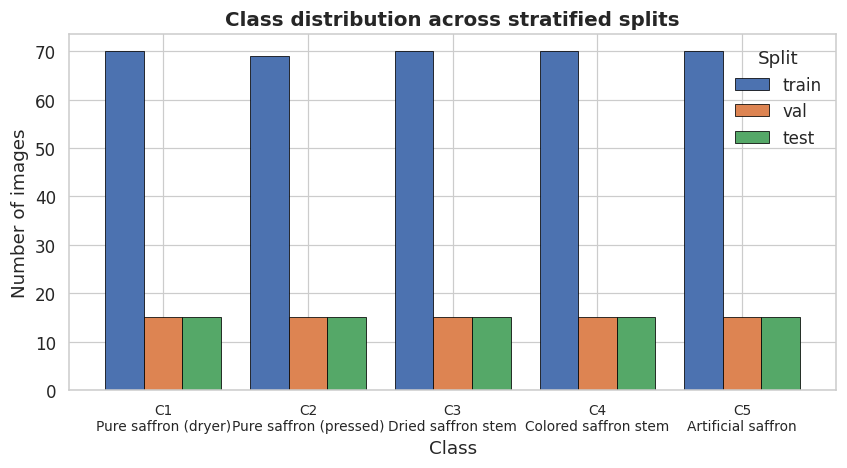

saved -> /content/saffron_project/outputs/class_distribution.png


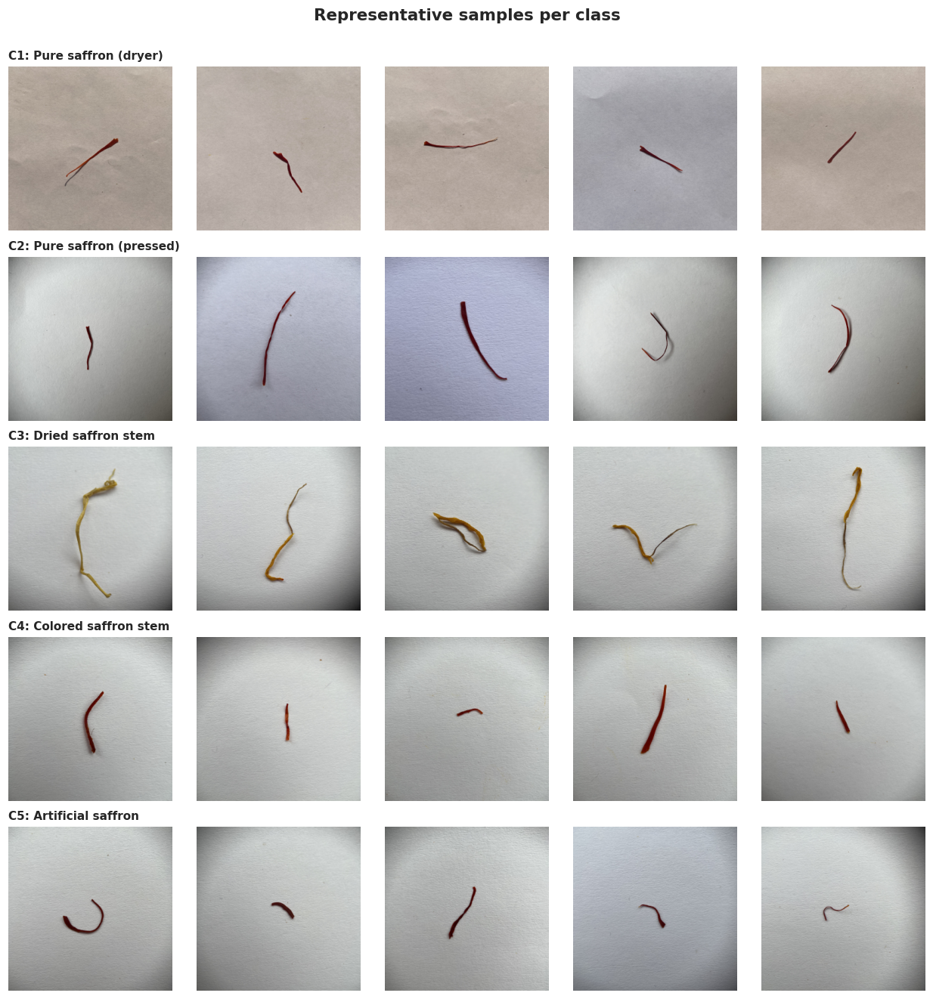

saved -> /content/saffron_project/outputs/dataset_samples.png


In [8]:
# Class distribution per split
fig, ax = plt.subplots(figsize=(9, 4.2))
split_df.drop(index="TOTAL").plot(kind="bar", ax=ax, color=PALETTE[:3], width=0.8, edgecolor="black", linewidth=0.5)
ax.set_title("Class distribution across stratified splits")
ax.set_xlabel("Class"); ax.set_ylabel("Number of images")
ax.set_xticklabels(CLASS_LABELS, rotation=0, fontsize=9)
ax.legend(title="Split")
save_fig(fig, OUTPUTS_DIR / "class_distribution.png")

# Example images per class
n_per_class = 5
fig, axes = plt.subplots(NUM_CLASSES, n_per_class, figsize=(2.3 * n_per_class, 2.4 * NUM_CLASSES))
axes = np.atleast_2d(axes)
rng = np.random.default_rng(SEED)
for r, cls in enumerate(CLASS_NAMES):
    idx = rng.choice(np.where(labels_all == r)[0], size=min(n_per_class, (labels_all == r).sum()), replace=False)
    for c in range(n_per_class):
        ax = axes[r, c]; ax.axis("off")
        if c < len(idx):
            ax.imshow(df["img_eval"].iloc[idx[c]])
        if c == 0:
            ax.set_title(CLASS_LABELS[r].replace("\n", ": "), loc="left", fontsize=10)
fig.suptitle("Representative samples per class", y=1.0, fontsize=14, fontweight="bold")
fig.tight_layout()
save_fig(fig, OUTPUTS_DIR / "dataset_samples.png")

---
## 3. Preprocessing

### 3.1 Normalisation inside the model

Each backbone expects a different input normalisation (EfficientNet rescales internally, ResNet50V2 expects `[-1, 1]`, DenseNet121 expects ImageNet mean/std). Rather than normalising in Python, a small `preprocess` block is placed **at the front of every model graph**. That has two benefits:

* The exported model accepts **raw RGB pixels in `[0, 255]`**, so a React / TensorFlow.js client only has to resize the image to `300 × 300`, with no preprocessing code to keep in sync.
* It is impossible to accidentally train with one normalisation and serve with another.

Only built-in Keras layers are used (no `Lambda` layers), so the model serialises and converts cleanly.

### 3.2 Data augmentation (Albumentations)

With only ~100 images per class, augmentation is the main defence against overfitting. The pipeline covers every transform in the brief:

| Requirement | Albumentations transform | Notes |
|---|---|---|
| Random crop | `RandomResizedCrop` | 60 to 100% of the cached image, rescaled to 300 px |
| Horizontal / vertical flip | `HorizontalFlip`, `VerticalFlip` | Threads have no canonical orientation |
| Rotation | `RandomRotate90` | Lossless 90° rotations |
| Shift-scale-rotate | `Affine` | The current API that replaces the deprecated `ShiftScaleRotate` |
| Brightness / contrast | `RandomBrightnessContrast` | Simulates lighting variation |
| Hue / saturation | `HueSaturationValue` | **Deliberately mild** (see below) |
| CLAHE | `CLAHE` | Local contrast, emphasises thread texture |
| Gaussian blur | `GaussianBlur` | Simulates slight defocus |

**Why colour augmentation is kept mild.** Colour is the primary physical cue separating pure stigma from dyed stems (C4) and synthetic threads (C5). Aggressive hue shifts could turn a C4 sample into something that looks like C1, teaching the model to ignore the very signal it needs. Hue is therefore limited to ±4 and saturation to ±12.

Validation and test images are **never** augmented; they are only resized, exactly like production inference.

In [9]:
train_transform = A.Compose([
    A.RandomResizedCrop(size=(IMG_SIZE, IMG_SIZE), scale=(0.60, 1.0), ratio=(0.85, 1.18), p=1.0),
    A.HorizontalFlip(p=0.5),
    A.VerticalFlip(p=0.5),
    A.RandomRotate90(p=0.5),
    A.Affine(scale=(0.90, 1.10), translate_percent=(-0.06, 0.06), rotate=(-20, 20),
             border_mode=cv2.BORDER_REFLECT_101, p=0.5),
    A.RandomBrightnessContrast(brightness_limit=0.15, contrast_limit=0.15, p=0.5),
    A.HueSaturationValue(hue_shift_limit=4, sat_shift_limit=12, val_shift_limit=10, p=0.3),
    A.CLAHE(clip_limit=2.0, tile_grid_size=(8, 8), p=0.15),
    A.GaussianBlur(blur_limit=(3, 5), p=0.15),
], seed=SEED)


class SaffronSequence(keras.utils.PyDataset):
    # Batches (image, one-hot label[, sample_weight]) with Albumentations applied on the fly.

    def __init__(self, images, labels_onehot, batch_size, transform=None, shuffle=True,
                 class_weights=None, seed=SEED, **kwargs):
        super().__init__(**kwargs)
        self.images, self.labels = images, labels_onehot
        self.batch_size, self.transform, self.shuffle = batch_size, transform, shuffle
        self.sample_w = None
        if class_weights is not None:
            cw = np.array([class_weights[i] for i in range(labels_onehot.shape[1])], dtype="float32")
            self.sample_w = cw[labels_onehot.argmax(1)]
        self.rng = np.random.default_rng(seed)
        self.indices = np.arange(len(images))
        if shuffle:
            self.rng.shuffle(self.indices)

    def __len__(self):
        return math.ceil(len(self.images) / self.batch_size)

    def __getitem__(self, idx):
        b = self.indices[idx * self.batch_size:(idx + 1) * self.batch_size]
        if self.transform is not None:
            x = np.stack([self.transform(image=self.images[i])["image"] for i in b])
        else:
            x = self.images[b]
        x = x.astype("float32")
        if self.sample_w is not None:
            return x, self.labels[b], self.sample_w[b]
        return x, self.labels[b]

    def on_epoch_end(self):
        if self.shuffle:
            self.rng.shuffle(self.indices)


def make_train_sequence(batch_size):
    return SaffronSequence(X_train_load, Y_train, batch_size, transform=train_transform, shuffle=True,
                           class_weights=CLASS_WEIGHTS, workers=WORKERS, use_multiprocessing=False)

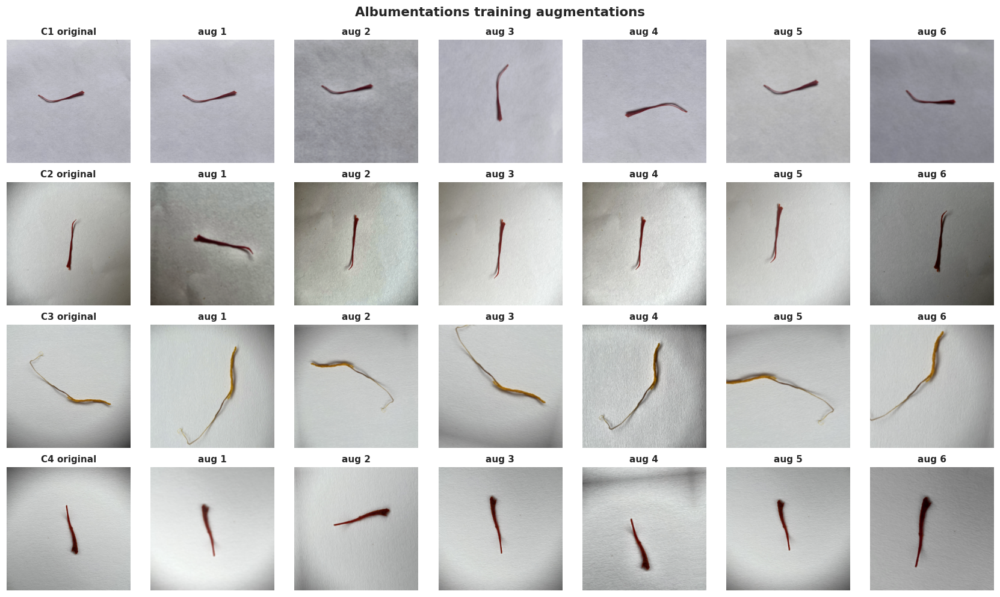

saved -> /content/saffron_project/outputs/augmentation_examples.png


In [10]:
# Visual check of the augmentation pipeline: each row is one image augmented 6 times
n_show, n_aug = min(4, NUM_CLASSES), 6
fig, axes = plt.subplots(n_show, n_aug + 1, figsize=(2.2 * (n_aug + 1), 2.3 * n_show))
axes = np.atleast_2d(axes)
for r in range(n_show):
    i = np.where(y_train == r)[0][0]
    axes[r, 0].imshow(X_train_eval[i]); axes[r, 0].set_title(f"{CLASS_NAMES[r]} original", fontsize=10)
    for c in range(1, n_aug + 1):
        axes[r, c].imshow(train_transform(image=X_train_load[i])["image"])
        axes[r, c].set_title(f"aug {c}", fontsize=10)
for ax in axes.ravel():
    ax.axis("off")
fig.suptitle("Albumentations training augmentations", fontsize=14, fontweight="bold")
fig.tight_layout()
save_fig(fig, OUTPUTS_DIR / "augmentation_examples.png")

---
## 4. Transfer Learning

Three ImageNet-pretrained backbones with different inductive biases are compared:

| Backbone | Params | Why it is a good candidate |
|---|---|---|
| **EfficientNetB3** | ~10.8 M | Compound-scaled, strong accuracy per FLOP, native 300 px input suits fine thread texture |
| **ResNet50V2** | ~23.6 M | Pre-activation residual network, very stable to fine-tune on small data |
| **DenseNet121** | ~7.0 M | Dense feature reuse, known to perform well on small fine-grained datasets |

**Architecture** (identical for all three):

```
image (300×300×3, raw 0-255)
 → preprocess      (backbone-specific normalisation, built-in Keras layers)
 → backbone        (ImageNet weights, include_top=False, BatchNorm kept in inference mode)
 → GlobalAveragePooling2D
 → Dropout(p)      (p tuned)
 → Dense(5)        "logits"      (float32)
 → Softmax         "predictions" (float32)
```

Logits and softmax are separate layers so that Grad-CAM can differentiate the **pre-softmax** score, which avoids vanishing gradients on highly confident predictions. Both are kept in `float32` for numerical stability under mixed precision.

**Freeze → fine-tune.** Phase 1 trains only the new head on top of the frozen backbone. Phase 2 unfreezes the top 30% of backbone layers and continues at a 10× lower learning rate. BatchNormalization layers stay frozen throughout, since updating their statistics with batches of 16 to 32 images destroys pretrained features.

In [11]:
BACKBONE_REGISTRY = {
    "EfficientNetB3": (keras.applications.EfficientNetB3, "none"),   # rescaling + normalisation built in
    "ResNet50V2":     (keras.applications.ResNet50V2,     "tf"),     # expects [-1, 1]
    "DenseNet121":    (keras.applications.DenseNet121,    "torch"),  # expects ImageNet mean / std
}
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD  = [0.229, 0.224, 0.225]


def make_preprocess(mode):
    if mode == "none":
        blocks = [keras.layers.Identity()]
    elif mode == "tf":
        blocks = [keras.layers.Rescaling(1.0 / 127.5, offset=-1.0)]
    elif mode == "torch":
        blocks = [keras.layers.Rescaling(1.0 / 255.0),
                  keras.layers.Normalization(mean=IMAGENET_MEAN, variance=[s ** 2 for s in IMAGENET_STD])]
    else:
        raise ValueError(mode)
    return keras.Sequential(blocks, name="preprocess")


def build_model(backbone_name, dropout, weights=IMAGENET_WEIGHTS):
    app_fn, mode = BACKBONE_REGISTRY[backbone_name]
    inputs = keras.Input(shape=(IMG_SIZE, IMG_SIZE, 3), name="image")
    x = make_preprocess(mode)(inputs)
    base = app_fn(include_top=False, weights=weights, input_shape=(IMG_SIZE, IMG_SIZE, 3))
    base.trainable = False
    x = base(x, training=False)                         # BatchNorm always in inference mode
    x = keras.layers.GlobalAveragePooling2D(name="gap")(x)
    x = keras.layers.Dropout(dropout, name="dropout")(x)
    logits = keras.layers.Dense(NUM_CLASSES, dtype="float32", name="logits")(x)
    outputs = keras.layers.Activation("softmax", dtype="float32", name="predictions")(logits)
    return keras.Model(inputs, outputs, name=f"saffron_{backbone_name.lower()}"), base


def get_backbone(model):
    return next(l for l in model.layers if isinstance(l, keras.Model) and l.name != "preprocess")


def unfreeze_top(base, fraction=FINETUNE_FRACTION):
    base.trainable = True
    cutoff = int(len(base.layers) * (1.0 - fraction))
    for i, layer in enumerate(base.layers):
        layer.trainable = (i >= cutoff) and not isinstance(layer, keras.layers.BatchNormalization)


def count_params(model):
    tr = int(sum(np.prod(v.shape) for v in model.trainable_weights))
    total = int(sum(np.prod(v.shape) for v in model.weights))
    return tr, total


# Quick structural check of each candidate
for name in BACKBONES:
    keras.backend.clear_session()
    m, b = build_model(name, dropout=0.3)
    tr0, tot = count_params(m)
    unfreeze_top(b)
    tr1, _ = count_params(m)
    print(f"{name:15s} total={tot/1e6:6.2f}M  trainable(frozen)={tr0/1e3:7.1f}K  "
          f"trainable(fine-tune)={tr1/1e6:5.2f}M  backbone layers={len(b.layers)}")
    del m, b
keras.backend.clear_session(); gc.collect()

43941136/43941136 ━━━━━━━━━━━━━━━━━━━━ 3s 0us/step
EfficientNetB3  total= 10.79M  trainable(frozen)=    7.7K  trainable(fine-tune)= 8.35M  backbone layers=385
94668760/94668760 ━━━━━━━━━━━━━━━━━━━━ 6s 0us/step
ResNet50V2      total= 23.58M  trainable(frozen)=   10.2K  trainable(fine-tune)=17.19M  backbone layers=190
29084464/29084464 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
DenseNet121     total=  7.04M  trainable(frozen)=    5.1K  trainable(fine-tune)= 2.86M  backbone layers=427


0

---
## 5. Training Strategy

| Component | Choice | Rationale |
|---|---|---|
| Optimiser | **AdamW** (weight decay 1e-4, not applied to biases / BN) | Decoupled weight decay regularises better than L2 in Adam |
| Loss | Categorical cross-entropy, **label smoothing 0.1** | Discourages over-confidence on a small dataset |
| LR schedule | **Cosine decay with 1-epoch warm-up** | Smooth annealing; warm-up protects pretrained weights |
| Plateau handling | **ReduceLROnPlateau** (×0.5 after 3 stagnant epochs on `val_loss`) | Extra decay when progress stalls |
| Early stopping | Patience 8 on validation macro-F1 | Stops wasted epochs |
| Checkpointing | Best validation macro-F1 weights per phase | Phase 2 only overwrites phase 1 if it genuinely improves |
| Mixed precision | `mixed_float16` on GPU | ~2× faster on T4 tensor cores |
| Class weighting | Automatic, only if imbalance > 1.2 | Dataset is balanced by default, so usually off |

**Combining cosine decay with ReduceLROnPlateau.** Keras' stock `ReduceLROnPlateau` cannot modify a learning rate that is controlled by a `LearningRateSchedule` object, and a plain `LearningRateScheduler` would overwrite any plateau reduction at the start of the next epoch. The `CosineWithPlateau` callback below implements both correctly: it computes the cosine value each epoch and multiplies it by a plateau factor that is halved whenever `val_loss` stalls.

**Why macro-F1 for selection.** Accuracy can hide a model that sacrifices one class (historically C5). Macro-F1 weights every class equally, so it directly targets the thesis model's weak spot.

In [12]:
class CosineWithPlateau(keras.callbacks.Callback):
    # Per-epoch cosine decay (with linear warm-up) multiplied by a ReduceLROnPlateau-style factor.

    def __init__(self, base_lr, total_epochs, warmup_epochs=WARMUP_EPOCHS, min_lr=MIN_LR,
                 factor=PLATEAU_FACTOR, patience=PLATEAU_PATIENCE, monitor="val_loss", verbose=0):
        super().__init__()
        self.base_lr, self.total_epochs, self.warmup_epochs = base_lr, total_epochs, warmup_epochs
        self.min_lr, self.factor, self.patience, self.monitor = min_lr, factor, patience, monitor
        self.verbose = verbose
        self.scale, self.best, self.wait, self.lrs = 1.0, np.inf, 0, []

    def _cosine(self, epoch):
        if epoch < self.warmup_epochs:
            return self.base_lr * (epoch + 1) / self.warmup_epochs
        span = max(1, self.total_epochs - self.warmup_epochs)
        progress = min(1.0, (epoch - self.warmup_epochs) / span)
        return self.min_lr + 0.5 * (self.base_lr - self.min_lr) * (1.0 + math.cos(math.pi * progress))

    def on_epoch_begin(self, epoch, logs=None):
        lr = max(self._cosine(epoch) * self.scale, self.min_lr)
        self.model.optimizer.learning_rate = lr
        self.lrs.append(float(lr))

    def on_epoch_end(self, epoch, logs=None):
        current = (logs or {}).get(self.monitor)
        if current is None:
            return
        if current < self.best - 1e-4:
            self.best, self.wait = current, 0
        else:
            self.wait += 1
            if self.wait >= self.patience:
                self.scale *= self.factor
                self.wait = 0
                if self.verbose:
                    print(f"  [plateau] epoch {epoch + 1}: LR scale reduced to {self.scale:.3g}")


def make_optimizer(lr):
    opt = keras.optimizers.AdamW(learning_rate=lr, weight_decay=WEIGHT_DECAY)
    opt.exclude_from_weight_decay(var_names=["bias", "gamma", "beta"])
    return opt


def compile_model(model, lr):
    model.compile(
        optimizer=make_optimizer(lr),
        loss=keras.losses.CategoricalCrossentropy(label_smoothing=LABEL_SMOOTHING),
        metrics=["accuracy", keras.metrics.F1Score(average="macro", name="f1")],
    )


def best_epoch(history):
    # Epoch with the highest val macro-F1; ties broken by the lowest val loss.
    f1, loss = history["val_f1"], history["val_loss"]
    return min(range(len(f1)), key=lambda i: (-f1[i], loss[i]))


def evaluate_split(model, X, y, batch_size=32):
    proba = model.predict(X.astype("float32"), batch_size=batch_size, verbose=0)
    pred = proba.argmax(1)
    return {
        "accuracy": float(accuracy_score(y, pred)),
        "macro_f1": float(f1_score(y, pred, average="macro", zero_division=0)),
        "loss": float(log_loss(y, np.clip(proba, 1e-7, 1.0), labels=list(range(NUM_CLASSES)))),
    }, proba


def run_phase(model, lr, epochs, batch_size, ckpt_path, initial_threshold=None, verbose=2):
    # Train one phase and return its history (checkpoint holds the best weights of this phase).
    compile_model(model, lr)
    if Path(ckpt_path).exists():
        Path(ckpt_path).unlink()
    lr_cb = CosineWithPlateau(lr, epochs, verbose=verbose)
    callbacks = [
        lr_cb,
        keras.callbacks.ModelCheckpoint(str(ckpt_path), monitor="val_f1", mode="max", save_best_only=True,
                                        save_weights_only=True, initial_value_threshold=initial_threshold),
        keras.callbacks.EarlyStopping(monitor="val_f1", mode="max", patience=EARLY_STOP_PATIENCE),
    ]
    hist = model.fit(make_train_sequence(batch_size), validation_data=(X_val_f, Y_val),
                     epochs=epochs, callbacks=callbacks, verbose=verbose)
    h = {k: [float(v) for v in vals] for k, vals in hist.history.items()}
    h["lr"] = lr_cb.lrs[:len(h["loss"])]
    return h

### 5.1 Lightweight hyperparameter search

For each backbone, `N_TRIALS` configurations are sampled from the grid of learning rate × batch size × dropout (the **same** sample for every backbone, for a fair comparison). Each trial trains only the head on the frozen backbone for `TUNE_EPOCHS` epochs, which is cheap but strongly predictive of how well a configuration fine-tunes. The configuration with the best validation macro-F1 (ties broken by validation loss) is carried forward to full training.

In [13]:
all_configs = [dict(zip(SEARCH_SPACE, vals)) for vals in itertools.product(*SEARCH_SPACE.values())]
TRIALS = random.Random(SEED).sample(all_configs, k=min(N_TRIALS, len(all_configs)))
print(f"Sampled {len(TRIALS)} of {len(all_configs)} configurations:")
display(pd.DataFrame(TRIALS))

tuning_rows, BEST_HPARAMS = [], {}
t_tune = time.time()
for name in BACKBONES:
    print(f"\n=== Tuning {name} ===")
    for t, cfg in enumerate(TRIALS):
        keras.backend.clear_session(); gc.collect()
        keras.utils.set_random_seed(SEED)
        model, _ = build_model(name, cfg["dropout"])
        compile_model(model, cfg["learning_rate"])
        t0 = time.time()
        hist = model.fit(make_train_sequence(cfg["batch_size"]), validation_data=(X_val_f, Y_val),
                         epochs=TUNE_EPOCHS, verbose=0,
                         callbacks=[CosineWithPlateau(cfg["learning_rate"], TUNE_EPOCHS)]).history
        e = best_epoch(hist)
        row = {"backbone": name, "trial": t, **cfg, "best_epoch": e + 1,
               "val_f1": hist["val_f1"][e], "val_accuracy": hist["val_accuracy"][e],
               "val_loss": hist["val_loss"][e], "seconds": round(time.time() - t0, 1)}
        tuning_rows.append(row)
        print(f"  trial {t}: lr={cfg['learning_rate']:.0e} bs={cfg['batch_size']:>2} drop={cfg['dropout']:.1f} "
              f"-> val_f1={row['val_f1']:.4f} val_acc={row['val_accuracy']:.4f} ({row['seconds']}s)")
        del model
    rows = [r for r in tuning_rows if r["backbone"] == name]
    best = min(rows, key=lambda r: (-r["val_f1"], r["val_loss"]))
    BEST_HPARAMS[name] = {k: best[k] for k in SEARCH_SPACE}
    print(f"  -> best for {name}: {BEST_HPARAMS[name]}")

tuning_df = pd.DataFrame(tuning_rows)
tuning_df.to_csv(OUTPUTS_DIR / "hyperparameter_search.csv", index=False)
print(f"\nHyperparameter search finished in {(time.time() - t_tune) / 60:.1f} min")
display(tuning_df.sort_values(["backbone", "val_f1"], ascending=[True, False]).round(4))

Sampled 4 of 8 configurations:


,learning_rate,batch_size,dropout
0,0.0010,16,0.4
1,0.0010,16,0.2
2,0.0005,16,0.4
3,0.0010,32,0.2



=== Tuning EfficientNetB3 ===
  trial 0: lr=1e-03 bs=16 drop=0.4 -> val_f1=0.8939 val_acc=0.8933 (113.0s)
  trial 1: lr=1e-03 bs=16 drop=0.2 -> val_f1=0.9195 val_acc=0.9200 (73.7s)
  trial 2: lr=5e-04 bs=16 drop=0.4 -> val_f1=0.8792 val_acc=0.8800 (71.5s)
  trial 3: lr=1e-03 bs=32 drop=0.2 -> val_f1=0.8939 val_acc=0.8933 (84.9s)
  -> best for EfficientNetB3: {'learning_rate': 0.001, 'batch_size': 16, 'dropout': 0.2}

=== Tuning ResNet50V2 ===
  trial 0: lr=1e-03 bs=16 drop=0.4 -> val_f1=0.8927 val_acc=0.8933 (47.6s)
  trial 1: lr=1e-03 bs=16 drop=0.2 -> val_f1=0.8928 val_acc=0.8933 (34.4s)
  trial 2: lr=5e-04 bs=16 drop=0.4 -> val_f1=0.8025 val_acc=0.8000 (35.0s)
  trial 3: lr=1e-03 bs=32 drop=0.2 -> val_f1=0.8676 val_acc=0.8667 (40.2s)
  -> best for ResNet50V2: {'learning_rate': 0.001, 'batch_size': 16, 'dropout': 0.2}

=== Tuning DenseNet121 ===
  trial 0: lr=1e-03 bs=16 drop=0.4 -> val_f1=0.8529 val_acc=0.8533 (87.9s)
  trial 1: lr=1e-03 bs=16 drop=0.2 -> val_f1=0.8529 val_acc=0.85

,backbone,trial,learning_rate,batch_size,dropout,best_epoch,val_f1,val_accuracy,val_loss,seconds
8,DenseNet121,0,0.0010,16,0.4,8,0.8529,0.8533,0.7714,87.9
9,DenseNet121,1,0.0010,16,0.2,8,0.8529,0.8533,0.7402,68.9
11,DenseNet121,3,0.0010,32,0.2,6,0.8236,0.8267,0.8776,76.6
10,DenseNet121,2,0.0005,16,0.4,8,0.7196,0.7467,0.9987,68.7
1,EfficientNetB3,1,0.0010,16,0.2,2,0.9195,0.9200,0.8064,73.7
0,EfficientNetB3,0,0.0010,16,0.4,8,0.8939,0.8933,0.7185,113.0
3,EfficientNetB3,3,0.0010,32,0.2,8,0.8939,0.8933,0.7392,84.9
2,EfficientNetB3,2,0.0005,16,0.4,8,0.8792,0.8800,0.8018,71.5
5,ResNet50V2,1,0.0010,16,0.2,5,0.8928,0.8933,0.7307,34.4
4,ResNet50V2,0,0.0010,16,0.4,8,0.8927,0.8933,0.7274,47.6


### 5.2 Full two-phase training of every backbone

Each backbone is trained with its best configuration: **phase 1** (frozen, `HEAD_EPOCHS`) followed by **phase 2** (top 30% unfrozen, `FINETUNE_EPOCHS`, LR ÷ 10). Phase 2's checkpoint is seeded with phase 1's best validation F1, so fine-tuning can only replace the phase 1 weights if it actually improves on them.

In [14]:
RESULTS = {}
for name in BACKBONES:
    hp = BEST_HPARAMS[name]
    print(f"\n{'=' * 70}\n{name}  |  {hp}\n{'=' * 70}")
    keras.backend.clear_session(); gc.collect()
    keras.utils.set_random_seed(SEED)
    model, base = build_model(name, hp["dropout"])
    t0 = time.time()

    # ---- Phase 1: frozen backbone ----
    print("Phase 1: training classification head (backbone frozen)")
    ck1 = CKPT_DIR / f"{name}_phase1.weights.h5"
    h1 = run_phase(model, hp["learning_rate"], HEAD_EPOCHS, hp["batch_size"], ck1)
    model.load_weights(ck1)
    p1_best = max(h1["val_f1"])

    # ---- Phase 2: fine-tune top of backbone ----
    unfreeze_top(base)
    tr, tot = count_params(model)
    print(f"\nPhase 2: fine-tuning top {int(FINETUNE_FRACTION * 100)}% of backbone "
          f"({tr / 1e6:.2f}M / {tot / 1e6:.2f}M params trainable)")
    ck2 = CKPT_DIR / f"{name}_phase2.weights.h5"
    h2 = run_phase(model, hp["learning_rate"] * FINETUNE_LR_FACTOR, FINETUNE_EPOCHS, hp["batch_size"],
                   ck2, initial_threshold=p1_best)
    improved = ck2.exists()
    model.load_weights(ck2 if improved else ck1)
    print(f"\nFine-tuning {'improved' if improved else 'did NOT improve'} on phase 1 "
          f"(phase 1 best val F1 = {p1_best:.4f}); using {'phase 2' if improved else 'phase 1'} weights.")

    final_ckpt = CKPT_DIR / f"{name}_best.weights.h5"
    model.save_weights(final_ckpt)
    val_metrics, val_proba = evaluate_split(model, X_val, y_val)
    RESULTS[name] = {
        "hparams": hp, "history_phase1": h1, "history_phase2": h2, "finetune_improved": improved,
        "val": val_metrics, "val_proba": val_proba, "weights": str(final_ckpt),
        "params_total": count_params(model)[1], "train_minutes": (time.time() - t0) / 60,
    }
    print(f"VALIDATION  acc={val_metrics['accuracy']:.4f}  macro-F1={val_metrics['macro_f1']:.4f}  "
          f"loss={val_metrics['loss']:.4f}  ({RESULTS[name]['train_minutes']:.1f} min)")
    del model, base
keras.backend.clear_session(); gc.collect()


EfficientNetB3  |  {'learning_rate': 0.001, 'batch_size': 16, 'dropout': 0.2}
Phase 1: training classification head (backbone frozen)
Epoch 1/15
22/22 - 60s - 3s/step - accuracy: 0.4413 - f1: 0.4399 - loss: 1.4558 - val_accuracy: 0.7733 - val_f1: 0.7443 - val_loss: 1.0387
Epoch 2/15
22/22 - 3s - 127ms/step - accuracy: 0.7479 - f1: 0.7457 - loss: 0.9792 - val_accuracy: 0.9200 - val_f1: 0.9204 - val_loss: 0.8014
Epoch 3/15
22/22 - 2s - 83ms/step - accuracy: 0.7851 - f1: 0.7814 - loss: 0.8528 - val_accuracy: 0.8533 - val_f1: 0.8496 - val_loss: 0.7697
Epoch 4/15
22/22 - 2s - 84ms/step - accuracy: 0.8109 - f1: 0.8103 - loss: 0.7840 - val_accuracy: 0.8933 - val_f1: 0.8939 - val_loss: 0.7190
Epoch 5/15
22/22 - 2s - 84ms/step - accuracy: 0.8424 - f1: 0.8413 - loss: 0.7639 - val_accuracy: 0.8933 - val_f1: 0.8939 - val_loss: 0.6981
Epoch 6/15
22/22 - 2s - 85ms/step - accuracy: 0.8539 - f1: 0.8519 - loss: 0.7336 - val_accuracy: 0.8800 - val_f1: 0.8801 - val_loss: 0.7069
Epoch 7/15
22/22 - 2s - 8

VALIDATION  acc=0.9733  macro-F1=0.9737  loss=0.2099  (3.7 min)


0

### 5.3 Automatic model selection

The winner is the backbone with the highest validation macro-F1, with ties broken by validation log-loss (the better-calibrated model wins).

,backbone,val_macro_f1,val_accuracy,val_loss,learning_rate,batch_size,dropout,finetune_improved,params_M,train_min
0,ResNet50V2,1.0000,1.0000,0.1246,0.001,16,0.2,True,23.58,2.6
1,EfficientNetB3,0.9867,0.9867,0.1555,0.001,16,0.2,True,10.79,3.5
2,DenseNet121,0.9737,0.9733,0.2099,0.001,16,0.2,True,7.04,3.7



Selected model: ResNet50V2  (val macro-F1 1.0000, val acc 1.0000)


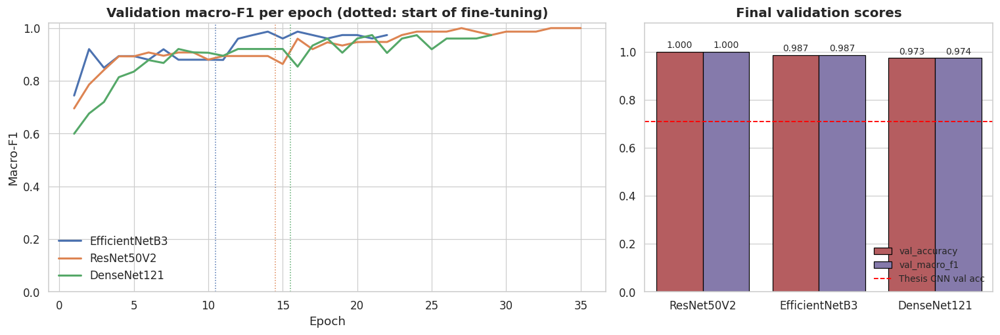

saved -> /content/saffron_project/outputs/model_comparison.png


In [15]:
comparison = pd.DataFrame([{
    "backbone": n,
    "val_macro_f1": r["val"]["macro_f1"],
    "val_accuracy": r["val"]["accuracy"],
    "val_loss": r["val"]["loss"],
    "learning_rate": r["hparams"]["learning_rate"],
    "batch_size": r["hparams"]["batch_size"],
    "dropout": r["hparams"]["dropout"],
    "finetune_improved": r["finetune_improved"],
    "params_M": round(r["params_total"] / 1e6, 2),
    "train_min": round(r["train_minutes"], 1),
} for n, r in RESULTS.items()]).sort_values(["val_macro_f1", "val_loss"], ascending=[False, True]).reset_index(drop=True)

BEST_NAME = comparison.loc[0, "backbone"]
BEST = RESULTS[BEST_NAME]
comparison.to_csv(OUTPUTS_DIR / "model_comparison.csv", index=False)
display(comparison.round(4))
print(f"\nSelected model: {BEST_NAME}  (val macro-F1 {BEST['val']['macro_f1']:.4f}, "
      f"val acc {BEST['val']['accuracy']:.4f})")

# Comparison figure: validation F1 curves + final scores
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.8), gridspec_kw={"width_ratios": [1.6, 1]})
for i, (n, r) in enumerate(RESULTS.items()):
    f1_curve = r["history_phase1"]["val_f1"] + r["history_phase2"]["val_f1"]
    ax1.plot(range(1, len(f1_curve) + 1), f1_curve, label=n, color=PALETTE[i], lw=2)
    ax1.axvline(len(r["history_phase1"]["val_f1"]) + 0.5, color=PALETTE[i], ls=":", lw=1)
ax1.set_title("Validation macro-F1 per epoch (dotted: start of fine-tuning)")
ax1.set_xlabel("Epoch"); ax1.set_ylabel("Macro-F1"); ax1.set_ylim(0, 1.02); ax1.legend()
m = comparison.melt(id_vars="backbone", value_vars=["val_accuracy", "val_macro_f1"], var_name="metric")
sns.barplot(data=m, x="backbone", y="value", hue="metric", ax=ax2, palette=PALETTE[3:5], edgecolor="black")
for c in ax2.containers:
    ax2.bar_label(c, fmt="%.3f", fontsize=9, padding=2)
ax2.axhline(THESIS_BASELINE["val_accuracy"], color="red", ls="--", lw=1.2, label="Thesis CNN val acc")
ax2.set_ylim(0, 1.12); ax2.set_title("Final validation scores"); ax2.set_xlabel(""); ax2.set_ylabel("")
ax2.legend(loc="lower right", fontsize=9)
fig.tight_layout()
save_fig(fig, OUTPUTS_DIR / "model_comparison.png")

### 5.4 Building the deployment model (float32)

The winning weights were trained under mixed precision, and Keras records a layer's dtype policy inside the saved file. A mixed-precision model runs slowly on CPUs and browsers and inserts float16 casts that TensorFlow.js handles poorly. The selected architecture is therefore **rebuilt under a pure `float32` policy** and the trained weights are loaded into it. A sanity check confirms that its predictions match the mixed-precision model.

In [16]:
keras.mixed_precision.set_global_policy("float32")
keras.backend.clear_session(); gc.collect()

best_model, best_base = build_model(BEST_NAME, BEST["hparams"]["dropout"])
unfreeze_top(best_base)                           # mirror the training-time trainable state (cosmetic)
best_model.load_weights(BEST["weights"])
best_model.trainable = False                      # inference artifact

val_metrics_fp32, val_proba_fp32 = evaluate_split(best_model, X_val, y_val)
agreement = float((val_proba_fp32.argmax(1) == BEST["val_proba"].argmax(1)).mean())
max_diff = float(np.abs(val_proba_fp32 - BEST["val_proba"]).max())
print(f"float32 vs mixed-precision: prediction agreement {agreement:.2%}, max |prob diff| {max_diff:.4f}")
print(f"float32 validation: acc={val_metrics_fp32['accuracy']:.4f} macro-F1={val_metrics_fp32['macro_f1']:.4f}")
assert agreement >= 0.97, "float32 rebuild diverges from the trained model; check weight loading."
best_model.summary(line_length=100)

float32 vs mixed-precision: prediction agreement 100.00%, max |prob diff| 0.0000
float32 validation: acc=1.0000 macro-F1=1.0000


Model: "saffron_resnet50v2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                               ┃ Output Shape                    ┃           Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ image (InputLayer)                         │ (None, 300, 300, 3)             │                 0 │
├────────────────────────────────────────────┼─────────────────────────────────┼───────────────────┤
│ preprocess (Sequential)                    │ (None, 300, 300, 3)             │                 0 │
├────────────────────────────────────────────┼─────────────────────────────────┼───────────────────┤
│ resnet50v2 (Functional)                    │ (None, 10, 10, 2048)            │        23,564,800 │
├────────────────────────────────────────────┼─────────────────────────────────┼───────────────────┤
│ gap (GlobalAveragePooling2D)               │ (None, 2048)                    │                 0 │
├────────────────────────────────────────────┼─────────────────────────────────┼───────────────────┤
│ dropout (Dropout)                          │ (None, 2048)                    │                 0 │
├────────────────────────────────────────────┼─────────────────────────────────┼───────────────────┤
│ logits (Dense)                             │ (None, 5)                       │            10,245 │
├────────────────────────────────────────────┼─────────────────────────────────┼───────────────────┤
│ predictions (Activation)                   │ (None, 5)                       │                 0 │
└────────────────────────────────────────────┴─────────────────────────────────┴───────────────────┘

 Total params: 23,575,045 (89.93 MB)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 23,575,045 (89.93 MB)

### 5.5 Training history of the selected model

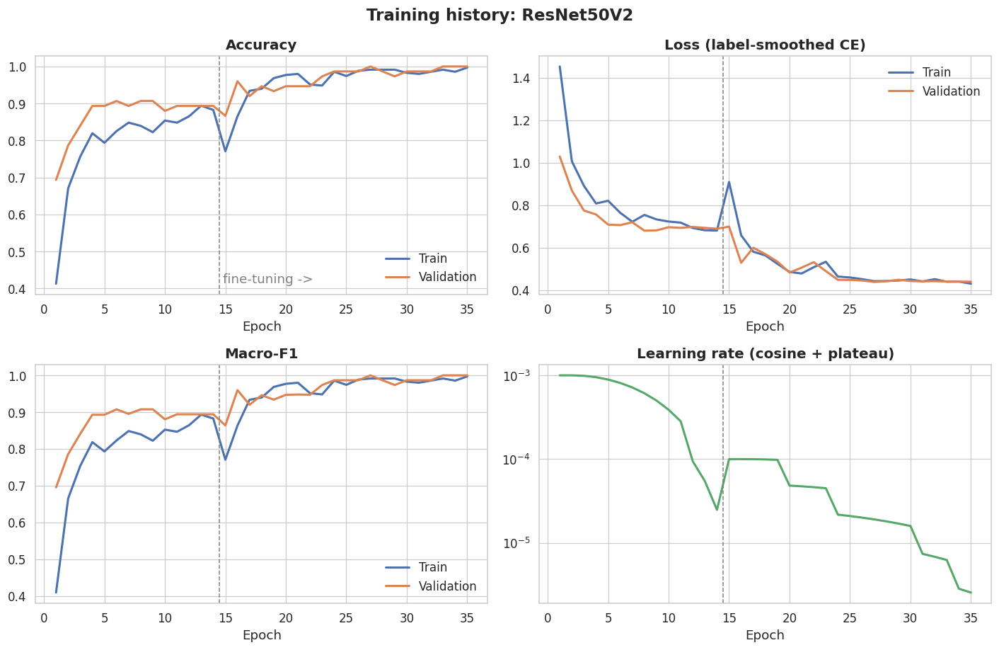

saved -> /content/saffron_project/outputs/training_history.png


In [17]:
h1, h2 = BEST["history_phase1"], BEST["history_phase2"]
H = {k: h1[k] + h2[k] for k in ("accuracy", "val_accuracy", "loss", "val_loss", "f1", "val_f1", "lr")}
epochs = np.arange(1, len(H["loss"]) + 1)
boundary = len(h1["loss"]) + 0.5

fig, axes = plt.subplots(2, 2, figsize=(13, 8.5))
panels = [("accuracy", "Accuracy"), ("loss", "Loss (label-smoothed CE)"), ("f1", "Macro-F1")]
for ax, (key, title) in zip(axes.ravel()[:3], panels):
    ax.plot(epochs, H[key], label="Train", color=PALETTE[0], lw=2)
    ax.plot(epochs, H[f"val_{key}"], label="Validation", color=PALETTE[1], lw=2)
    ax.axvline(boundary, color="grey", ls="--", lw=1)
    ax.set_title(title); ax.set_xlabel("Epoch"); ax.legend()
axes[0, 0].text(boundary + 0.3, 0.05, "fine-tuning ->", color="grey", transform=axes[0, 0].get_xaxis_transform())
ax = axes[1, 1]
ax.plot(epochs, H["lr"], color=PALETTE[2], lw=2); ax.axvline(boundary, color="grey", ls="--", lw=1)
ax.set_yscale("log"); ax.set_title("Learning rate (cosine + plateau)"); ax.set_xlabel("Epoch")
fig.suptitle(f"Training history: {BEST_NAME}", fontsize=15, fontweight="bold")
fig.tight_layout()
save_fig(fig, OUTPUTS_DIR / "training_history.png")

---
## 6. Evaluation

Everything in this section uses the **held-out test set**, evaluated once, with the selected float32 model.

In [18]:
test_proba = best_model.predict(X_test.astype("float32"), batch_size=32, verbose=0)
test_pred = test_proba.argmax(1)
test_conf = test_proba.max(1)
Y_test_bin = label_binarize(y_test, classes=list(range(NUM_CLASSES)))
if NUM_CLASSES == 2:
    Y_test_bin = np.hstack([1 - Y_test_bin, Y_test_bin])

test_acc = accuracy_score(y_test, test_pred)
test_macro_f1 = f1_score(y_test, test_pred, average="macro", zero_division=0)
test_weighted_f1 = f1_score(y_test, test_pred, average="weighted", zero_division=0)
try:
    test_auc_macro = roc_auc_score(Y_test_bin, test_proba, average="macro", multi_class="ovr")
except ValueError:
    test_auc_macro = float("nan")

print(f"TEST  accuracy      : {test_acc:.4f}   (thesis CNN val accuracy: {THESIS_BASELINE['val_accuracy']:.4f})")
print(f"TEST  macro-F1      : {test_macro_f1:.4f}")
print(f"TEST  weighted-F1   : {test_weighted_f1:.4f}")
print(f"TEST  macro ROC-AUC : {test_auc_macro:.4f}\n")

report = classification_report(y_test, test_pred, target_names=CLASS_NAMES, digits=4,
                               output_dict=True, zero_division=0)
report_df = pd.DataFrame(report).T
report_df.to_csv(OUTPUTS_DIR / "classification_report.csv")
display(report_df.round(4))

TEST  accuracy      : 0.9733   (thesis CNN val accuracy: 0.7083)
TEST  macro-F1      : 0.9732
TEST  weighted-F1   : 0.9732
TEST  macro ROC-AUC : 0.9993



,precision,recall,f1-score,support
C1,1.0000,1.0000,1.0000,15.0000
C2,1.0000,1.0000,1.0000,15.0000
C3,1.0000,1.0000,1.0000,15.0000
C4,1.0000,0.8667,0.9286,15.0000
C5,0.8824,1.0000,0.9375,15.0000
accuracy,0.9733,0.9733,0.9733,0.9733
macro avg,0.9765,0.9733,0.9732,75.0000
weighted avg,0.9765,0.9733,0.9732,75.0000


### 6.1 Confusion matrix

Counts on the left and row-normalised recall on the right. Pay particular attention to the **C4 / C5** cells, the main failure mode of the original CNN.

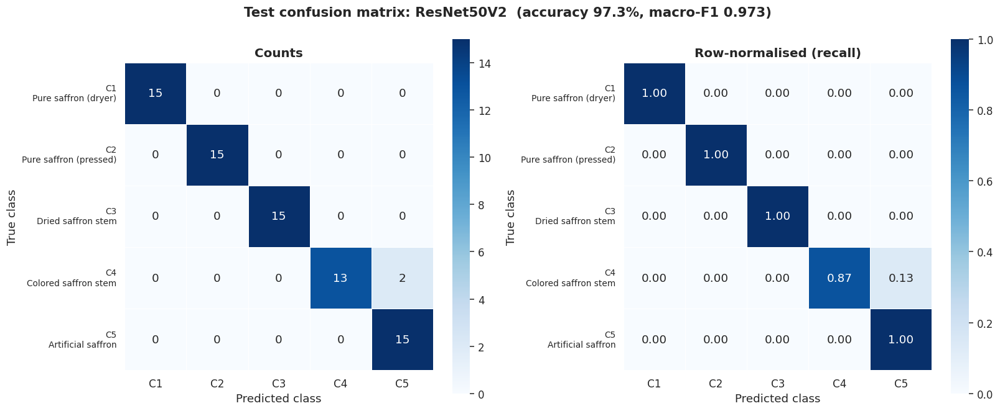

saved -> /content/saffron_project/outputs/confusion_matrix.png


In [19]:
cm = confusion_matrix(y_test, test_pred, labels=list(range(NUM_CLASSES)))
cm_norm = cm.astype(float) / np.maximum(cm.sum(1, keepdims=True), 1)

fig, axes = plt.subplots(1, 2, figsize=(15, 6.2))
for ax, mat, fmt, title in [(axes[0], cm, "d", "Counts"), (axes[1], cm_norm, ".2f", "Row-normalised (recall)")]:
    sns.heatmap(mat, annot=True, fmt=fmt, cmap="Blues", cbar=True, square=True, ax=ax,
                xticklabels=CLASS_NAMES, yticklabels=CLASS_LABELS, linewidths=0.5, linecolor="white",
                annot_kws={"size": 12}, vmin=0, vmax=(None if fmt == "d" else 1))
    ax.set_title(title); ax.set_xlabel("Predicted class"); ax.set_ylabel("True class")
    ax.tick_params(axis="y", rotation=0, labelsize=9)
fig.suptitle(f"Test confusion matrix: {BEST_NAME}  (accuracy {test_acc:.1%}, macro-F1 {test_macro_f1:.3f})",
             fontsize=14, fontweight="bold")
fig.tight_layout()
save_fig(fig, OUTPUTS_DIR / "confusion_matrix.png")

### 6.2 ROC and precision-recall curves (one-vs-rest)

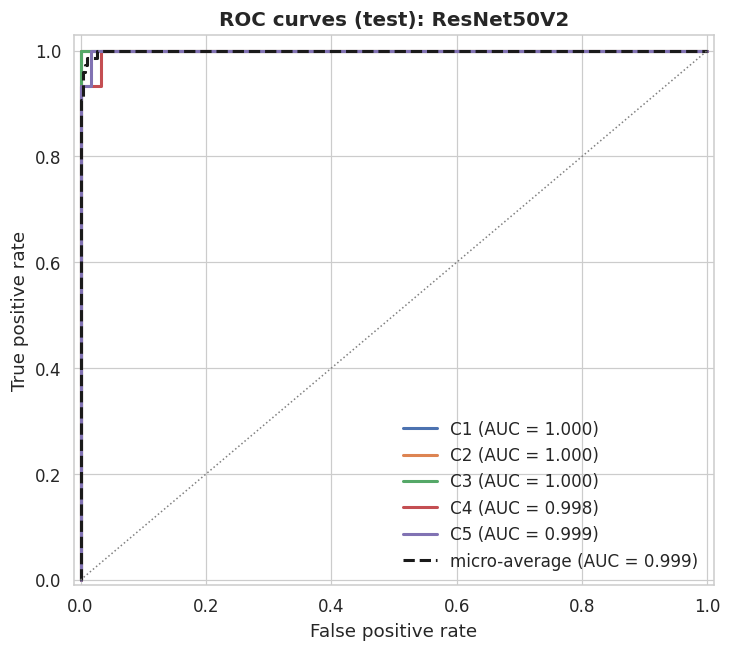

saved -> /content/saffron_project/outputs/roc_curves.png


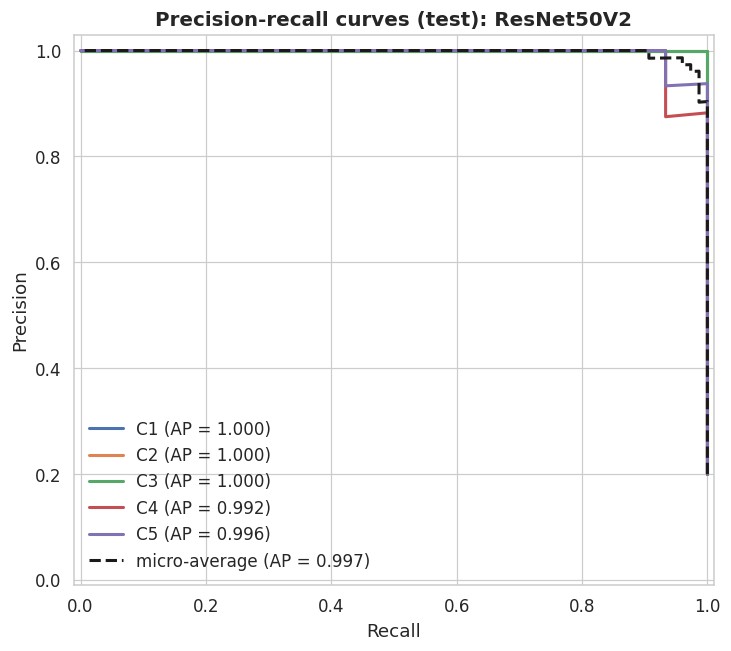

saved -> /content/saffron_project/outputs/precision_recall_curves.png


In [20]:
def _plot_curves(kind):
    fig, ax = plt.subplots(figsize=(7.5, 6.5))
    summary = {}
    for i, cls in enumerate(CLASS_NAMES):
        if Y_test_bin[:, i].sum() == 0:
            continue
        if kind == "roc":
            fpr, tpr, _ = roc_curve(Y_test_bin[:, i], test_proba[:, i]); score = auc(fpr, tpr)
            ax.plot(fpr, tpr, lw=2, color=PALETTE[i % 10], label=f"{cls} (AUC = {score:.3f})")
        else:
            prec, rec, _ = precision_recall_curve(Y_test_bin[:, i], test_proba[:, i])
            score = average_precision_score(Y_test_bin[:, i], test_proba[:, i])
            ax.plot(rec, prec, lw=2, color=PALETTE[i % 10], label=f"{cls} (AP = {score:.3f})")
        summary[cls] = float(score)
    if kind == "roc":
        fpr, tpr, _ = roc_curve(Y_test_bin.ravel(), test_proba.ravel())
        ax.plot(fpr, tpr, "k--", lw=2, label=f"micro-average (AUC = {auc(fpr, tpr):.3f})")
        ax.plot([0, 1], [0, 1], color="grey", lw=1, ls=":")
        ax.set_xlabel("False positive rate"); ax.set_ylabel("True positive rate")
        ax.set_title(f"ROC curves (test): {BEST_NAME}"); ax.legend(loc="lower right")
    else:
        prec, rec, _ = precision_recall_curve(Y_test_bin.ravel(), test_proba.ravel())
        ap = average_precision_score(Y_test_bin, test_proba, average="micro")
        ax.plot(rec, prec, "k--", lw=2, label=f"micro-average (AP = {ap:.3f})")
        ax.set_xlabel("Recall"); ax.set_ylabel("Precision")
        ax.set_title(f"Precision-recall curves (test): {BEST_NAME}"); ax.legend(loc="lower left")
    ax.set_xlim(-0.01, 1.01); ax.set_ylim(-0.01, 1.03)
    save_fig(fig, OUTPUTS_DIR / ("roc_curves.png" if kind == "roc" else "precision_recall_curves.png"))
    return summary

ROC_AUC = _plot_curves("roc")
AVG_PRECISION = _plot_curves("pr")

### 6.3 Per-class F1 vs. the thesis baseline

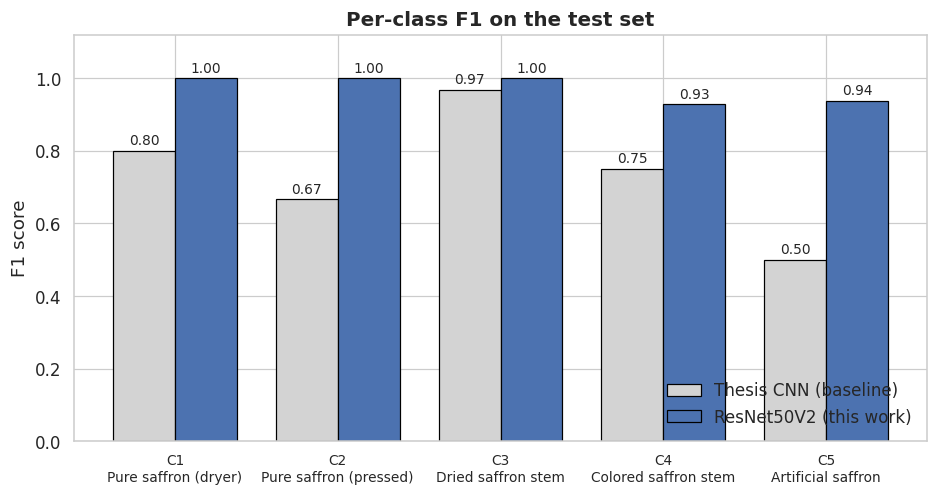

saved -> /content/saffron_project/outputs/per_class_f1.png


In [21]:
per_class_f1 = {c: float(report[c]["f1-score"]) for c in CLASS_NAMES}
has_baseline = set(CLASS_NAMES) == set(THESIS_BASELINE["per_class_f1"])

fig, ax = plt.subplots(figsize=(10, 4.8))
x = np.arange(NUM_CLASSES); w = 0.38 if has_baseline else 0.6
if has_baseline:
    b0 = ax.bar(x - w / 2, [THESIS_BASELINE["per_class_f1"][c] for c in CLASS_NAMES], w,
                label="Thesis CNN (baseline)", color="lightgrey", edgecolor="black")
    ax.bar_label(b0, fmt="%.2f", fontsize=9, padding=2)
b1 = ax.bar(x + (w / 2 if has_baseline else 0), [per_class_f1[c] for c in CLASS_NAMES], w,
            label=f"{BEST_NAME} (this work)", color=PALETTE[0], edgecolor="black")
ax.bar_label(b1, fmt="%.2f", fontsize=9, padding=2)
ax.set_xticks(x); ax.set_xticklabels(CLASS_LABELS, fontsize=9)
ax.set_ylim(0, 1.12); ax.set_ylabel("F1 score"); ax.legend(loc="lower right")
ax.set_title("Per-class F1 on the test set")
save_fig(fig, OUTPUTS_DIR / "per_class_f1.png")

### 6.4 Sample predictions

Green titles are correct predictions, red titles are errors. The confidence shown is the softmax probability of the predicted class.

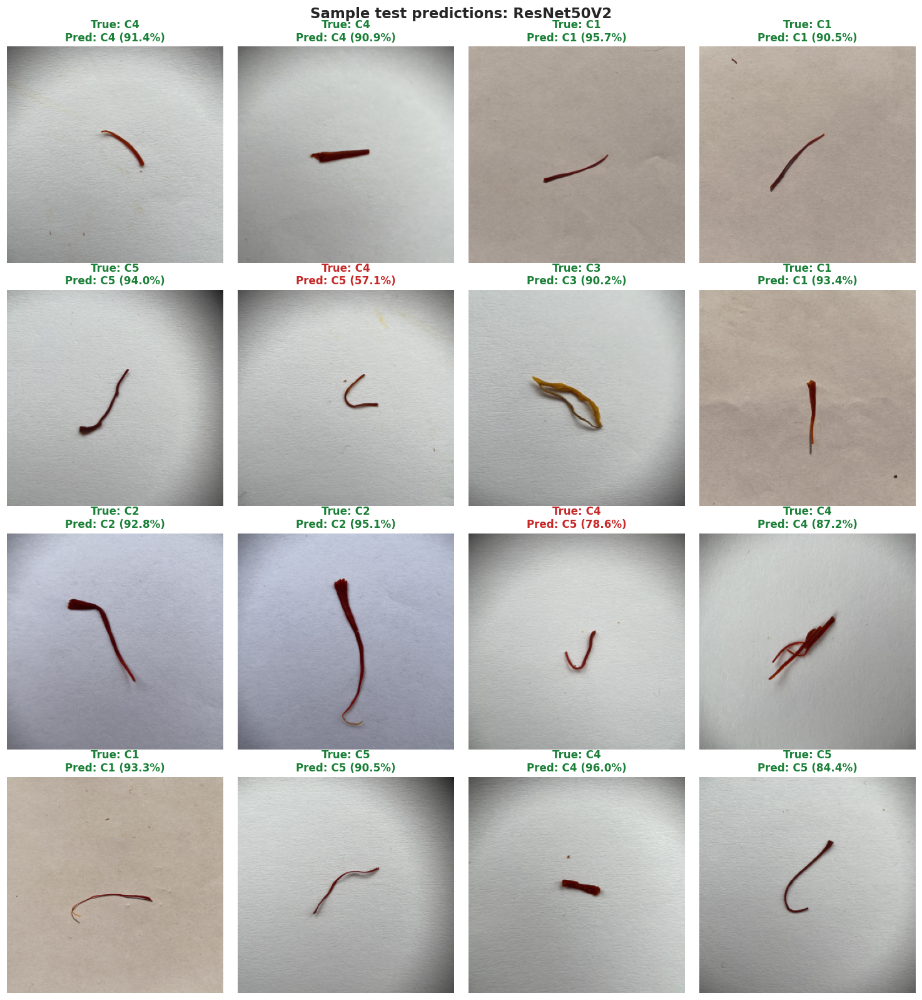

saved -> /content/saffron_project/outputs/sample_predictions.png


In [22]:
rng = np.random.default_rng(SEED)
wrong = np.where(test_pred != y_test)[0]
right = np.where(test_pred == y_test)[0]
n_show = min(16, len(y_test))
n_wrong = min(len(wrong), 4)
show_idx = np.concatenate([rng.choice(wrong, n_wrong, replace=False) if n_wrong else np.array([], int),
                           rng.choice(right, min(n_show - n_wrong, len(right)), replace=False)]).astype(int)
rng.shuffle(show_idx)

cols = 4; rows = math.ceil(len(show_idx) / cols)
fig, axes = plt.subplots(rows, cols, figsize=(3.4 * cols, 3.7 * rows))
for ax in np.atleast_1d(axes).ravel():
    ax.axis("off")
for ax, i in zip(np.atleast_1d(axes).ravel(), show_idx):
    ok = test_pred[i] == y_test[i]
    ax.imshow(X_test[i])
    ax.set_title(f"True: {CLASS_NAMES[y_test[i]]}\nPred: {CLASS_NAMES[test_pred[i]]} ({test_conf[i]:.1%})",
                 color=("#1a7f37" if ok else "#c62828"), fontsize=11)
fig.suptitle(f"Sample test predictions: {BEST_NAME}", fontsize=15, fontweight="bold")
fig.tight_layout()
save_fig(fig, OUTPUTS_DIR / "sample_predictions.png")

---
## 7. Explainability (Grad-CAM)

Grad-CAM (Selvaraju et al., 2017) highlights the image regions that most increased the score of the predicted class. It weights the final convolutional feature maps by the spatial average of the gradient of the class **logit** and keeps the positive evidence.

This is a useful check for a food-fraud classifier. A trustworthy model should focus on the **threads themselves** (their colour, trumpet-shaped stigma tips, surface texture), not on the background, the container, or lighting artefacts. The samples below include, for every class, the most confident correct prediction and the least confident one, plus any misclassifications.

Generating Grad-CAM for 12 test images using backbone 'resnet50v2'
Saved 12 Grad-CAM figures to /content/saffron_project/outputs/gradcam


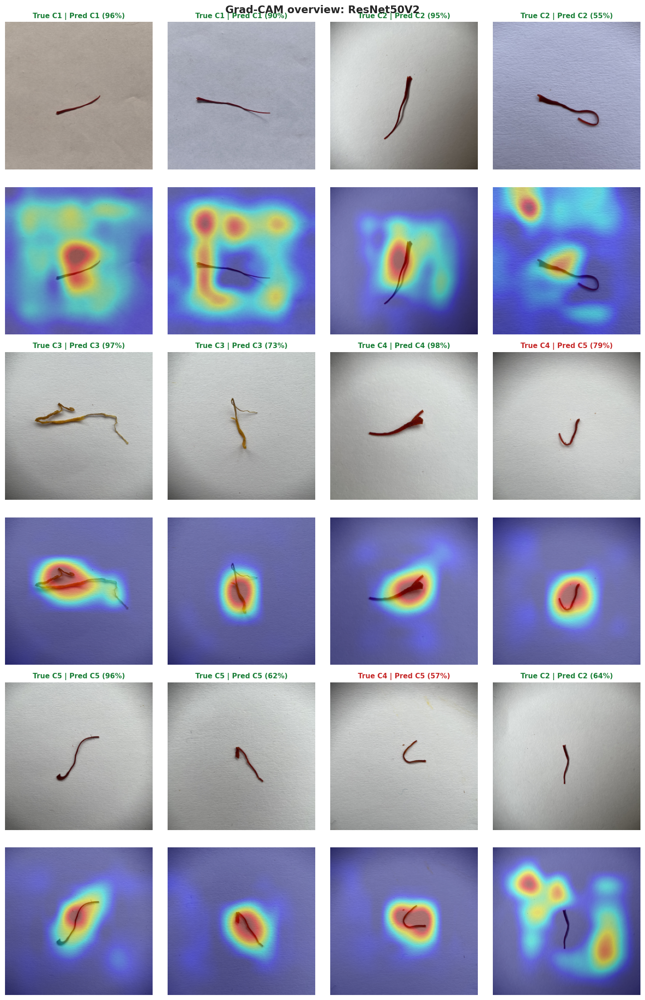

saved -> /content/saffron_project/outputs/gradcam/gradcam_overview.png


In [23]:
GRAD_BACKBONE = get_backbone(best_model)
GRAD_LAYERS = [best_model.get_layer(n) for n in ("preprocess", "gap", "dropout", "logits", "predictions")]


def grad_cam(image_uint8, class_index=None):
    # Returns (heatmap in [0,1] at IMG_SIZE, predicted index, softmax probabilities).
    pre, gap, drop, logits_layer, softmax_layer = GRAD_LAYERS
    x = tf.convert_to_tensor(image_uint8[None].astype("float32"))
    with tf.GradientTape() as tape:
        fmap = GRAD_BACKBONE(pre(x), training=False)
        tape.watch(fmap)
        logits = logits_layer(drop(gap(fmap), training=False))
        probs = softmax_layer(logits)
        idx = int(tf.argmax(probs[0])) if class_index is None else int(class_index)
        score = logits[:, idx]
    grads = tape.gradient(score, fmap)[0]
    weights = tf.reduce_mean(grads, axis=(0, 1))
    cam = tf.nn.relu(tf.reduce_sum(fmap[0] * weights, axis=-1)).numpy()
    cam = cam / cam.max() if cam.max() > 0 else cam
    cam = cv2.resize(cam.astype("float32"), (IMG_SIZE, IMG_SIZE), interpolation=cv2.INTER_CUBIC)
    return np.clip(cam, 0, 1), idx, probs[0].numpy()


def colorize(cam):
    return cv2.cvtColor(cv2.applyColorMap(np.uint8(255 * cam), cv2.COLORMAP_JET), cv2.COLOR_BGR2RGB)


def overlay(img, cam, alpha=0.45):
    return np.uint8(np.clip((1 - alpha) * img + alpha * colorize(cam), 0, 255))


# ---- choose informative samples ----
chosen = []
for c in range(NUM_CLASSES):
    idx_c = np.where(y_test == c)[0]
    if len(idx_c) == 0:
        continue
    correct_c = idx_c[test_pred[idx_c] == c]
    if len(correct_c):
        chosen.append(int(correct_c[np.argmax(test_conf[correct_c])]))        # most confident correct
    lowest = int(idx_c[np.argmin(test_proba[idx_c, c])])                      # hardest example of the class
    if lowest not in chosen:
        chosen.append(lowest)
for i in wrong:
    if len(chosen) >= N_GRADCAM:
        break
    if int(i) not in chosen:
        chosen.append(int(i))
for i in rng.permutation(len(y_test)):
    if len(chosen) >= max(N_GRADCAM, 10):
        break
    if int(i) not in chosen:
        chosen.append(int(i))
chosen = chosen[:max(N_GRADCAM, 10)]
print(f"Generating Grad-CAM for {len(chosen)} test images using backbone '{GRAD_BACKBONE.name}'")

gradcam_rows = []
for k, i in enumerate(chosen):
    img = X_test[i]
    cam, pred_idx, probs = grad_cam(img)
    true_c, pred_c, conf = CLASS_NAMES[y_test[i]], CLASS_NAMES[pred_idx], float(probs[pred_idx])
    fig, axes = plt.subplots(1, 3, figsize=(12, 4.3))
    for ax, im, t in zip(axes, [img, colorize(cam), overlay(img, cam)], ["Original", "Grad-CAM heatmap", "Overlay"]):
        ax.imshow(im); ax.set_title(t); ax.axis("off")
    ok = pred_idx == y_test[i]
    fig.suptitle(f"True: {true_c}  |  Predicted: {pred_c}  |  Confidence: {conf:.1%}",
                 color=("#1a7f37" if ok else "#c62828"), fontsize=14, fontweight="bold")
    fig.tight_layout()
    fname = GRADCAM_DIR / f"gradcam_{k + 1:02d}_true-{true_c}_pred-{pred_c}.png"
    fig.savefig(fname, dpi=200, bbox_inches="tight", facecolor="white")
    plt.close(fig)
    gradcam_rows.append({"file": fname.name, "true": true_c, "predicted": pred_c,
                         "confidence": round(conf, 4), "correct": bool(ok), "_img": img, "_cam": cam})
print(f"Saved {len(gradcam_rows)} Grad-CAM figures to {GRADCAM_DIR}")

# ---- overview grid ----
cols = 4; rows = math.ceil(len(gradcam_rows) / cols)
fig, axes = plt.subplots(rows * 2, cols, figsize=(3.3 * cols, 3.4 * rows * 2))
axes = np.atleast_2d(axes)
for ax in axes.ravel():
    ax.axis("off")
for k, r in enumerate(gradcam_rows):
    rr, cc = (k // cols) * 2, k % cols
    axes[rr, cc].imshow(r["_img"])
    axes[rr, cc].set_title(f"True {r['true']} | Pred {r['predicted']} ({r['confidence']:.0%})",
                           fontsize=10, color=("#1a7f37" if r["correct"] else "#c62828"))
    axes[rr + 1, cc].imshow(overlay(r["_img"], r["_cam"]))
fig.suptitle(f"Grad-CAM overview: {BEST_NAME}", fontsize=15, fontweight="bold")
fig.tight_layout()
save_fig(fig, GRADCAM_DIR / "gradcam_overview.png")

pd.DataFrame([{k: v for k, v in r.items() if not k.startswith("_")} for r in gradcam_rows]) \
  .to_csv(GRADCAM_DIR / "gradcam_index.csv", index=False)

---
## 8. Export Artifacts

| Artifact | Purpose |
|---|---|
| `models/best_model.keras` | Selected model, float32, preprocessing built in |
| `models/class_names.json` | Output index → class name mapping |
| `models/saved_model/` | TensorFlow SavedModel for TensorFlow.js / TF Serving conversion |
| `outputs/metrics.json` | Test / validation metrics, hyperparameters, deployment contract, environment |
| `outputs/classification_report.csv` | Per-class precision, recall, F1 |
| `outputs/*.png` | All figures (300 dpi) |
| `outputs/gradcam/` | Individual Grad-CAM panels, overview grid, and index CSV |

**Deployment contract** (also written into `metrics.json`): input tensor `image`, shape `[N, 300, 300, 3]`, `float32` RGB values in **`[0, 255]`** (resize only, no normalisation), output softmax probabilities ordered as in `class_names.json`.

For a React app, convert the SavedModel with the TensorFlow.js converter, for example:
`tensorflowjs_converter --input_format=tf_saved_model models/saved_model models/tfjs`

In [24]:
# ---- model + labels ----
model_path = MODELS_DIR / "best_model.keras"
best_model.save(model_path)
with open(MODELS_DIR / "class_names.json", "w") as f:
    json.dump(CLASS_NAMES, f, indent=2)

# Round-trip check: the saved file must reproduce the in-memory predictions
reloaded = keras.models.load_model(model_path)
reload_proba = reloaded.predict(X_test.astype("float32"), batch_size=32, verbose=0)
assert np.allclose(reload_proba, test_proba, atol=1e-4), "Reloaded model predictions differ!"
print(f"Saved and verified {model_path} ({model_path.stat().st_size / 1e6:.1f} MB)")

# SavedModel for TensorFlow.js / serving (non-fatal if the export API is unavailable)
saved_model_dir = MODELS_DIR / "saved_model"
try:
    if saved_model_dir.exists():
        shutil.rmtree(saved_model_dir)
    try:
        reloaded.export(str(saved_model_dir), verbose=False)
    except TypeError:                     # older Keras 3 releases without `verbose`
        reloaded.export(str(saved_model_dir))
    print(f"Exported SavedModel -> {saved_model_dir}")
except Exception as e:  # noqa: BLE001
    print(f"SavedModel export skipped: {type(e).__name__}: {e}")
del reloaded

Saved and verified /content/saffron_project/models/best_model.keras (95.0 MB)
Exported SavedModel -> /content/saffron_project/models/saved_model


In [25]:
def _to_builtin(o):
    if isinstance(o, (np.integer,)):  return int(o)
    if isinstance(o, (np.floating,)): return float(o)
    if isinstance(o, np.ndarray):     return o.tolist()
    if isinstance(o, Path):           return str(o)
    raise TypeError(type(o))

metrics = {
    "project": "Saffron adulteration detection (transfer learning)",
    "generated_utc": datetime.now(timezone.utc).isoformat(timespec="seconds"),
    "best_model": BEST_NAME,
    "selection_criterion": "highest validation macro-F1 (ties: lowest validation log-loss)",
    "hyperparameters": {
        **BEST["hparams"], "img_size": IMG_SIZE, "optimizer": "AdamW", "weight_decay": WEIGHT_DECAY,
        "label_smoothing": LABEL_SMOOTHING, "head_epochs_max": HEAD_EPOCHS,
        "finetune_epochs_max": FINETUNE_EPOCHS, "finetune_fraction": FINETUNE_FRACTION,
        "finetune_lr_factor": FINETUNE_LR_FACTOR, "finetune_improved": BEST["finetune_improved"],
        "class_weights": CLASS_WEIGHTS, "mixed_precision_training": USE_MIXED_PRECISION, "seed": SEED,
    },
    "test": {
        "n_images": int(len(y_test)),
        "accuracy": test_acc, "macro_f1": test_macro_f1, "weighted_f1": test_weighted_f1,
        "macro_roc_auc_ovr": test_auc_macro,
        "per_class": {c: {"precision": report[c]["precision"], "recall": report[c]["recall"],
                          "f1": report[c]["f1-score"], "support": int(report[c]["support"]),
                          "roc_auc": ROC_AUC.get(c), "average_precision": AVG_PRECISION.get(c)}
                      for c in CLASS_NAMES},
        "confusion_matrix": cm.tolist(),
    },
    "validation": {"n_images": int(len(y_val)), **val_metrics_fp32},
    "model_comparison": comparison.to_dict(orient="records"),
    "thesis_baseline": THESIS_BASELINE,
    "data": {
        "data_dir": str(DATA_DIR), "n_valid_images": int(len(df)), "n_rejected": len(rejected),
        "split_counts": {s: {c: int(split_df.loc[c, s]) for c in CLASS_NAMES} for s in ("train", "val", "test")},
    },
    "deployment": {
        "input_name": "image", "input_shape": [None, IMG_SIZE, IMG_SIZE, 3], "input_dtype": "float32",
        "input_range": "raw RGB pixel values in [0, 255]; resize to IMG_SIZE x IMG_SIZE; normalisation is built into the model",
        "output": "softmax probabilities, index order = class_names.json",
        "class_names": CLASS_NAMES,
        "class_descriptions": {c: CLASS_DESCRIPTIONS.get(c, c) for c in CLASS_NAMES},
    },
    "environment": {"tensorflow": tf.__version__, "keras": keras.__version__,
                    "albumentations": A.__version__, "opencv": cv2.__version__, "gpu": gpu_name},
}
with open(OUTPUTS_DIR / "metrics.json", "w") as f:
    json.dump(metrics, f, indent=2, default=_to_builtin)
print(f"saved -> {OUTPUTS_DIR / 'metrics.json'}")

# ---- clean temporary checkpoints: only the best model is kept ----
shutil.rmtree(CKPT_DIR, ignore_errors=True)

# ---- persist to Google Drive and create a downloadable zip ----
archive = shutil.make_archive(str(PROJECT_DIR.parent / "saffron_artifacts"), "zip", PROJECT_DIR)
if IN_COLAB and Path("/content/drive/MyDrive").exists():
    for sub in ("models", "outputs"):
        shutil.copytree(PROJECT_DIR / sub, DRIVE_EXPORT_DIR / sub, dirs_exist_ok=True)
    shutil.copy2(archive, DRIVE_EXPORT_DIR / "saffron_artifacts.zip")
    print(f"Artifacts copied to Google Drive: {DRIVE_EXPORT_DIR}")
print(f"Zip archive: {archive}")

saved -> /content/saffron_project/outputs/metrics.json
Artifacts copied to Google Drive: /content/drive/MyDrive/saffron_adulteration_artifacts
Zip archive: /content/saffron_artifacts.zip


In [26]:
print("=" * 70)
print(f" FINAL SUMMARY: {BEST_NAME}")
print("=" * 70)
print(f" Test accuracy    : {test_acc:.4f}   (thesis CNN: ~{THESIS_BASELINE['val_accuracy']:.4f} val)")
print(f" Test macro-F1    : {test_macro_f1:.4f}")
print(f" Test macro AUC   : {test_auc_macro:.4f}")
for c in CLASS_NAMES:
    base = THESIS_BASELINE["per_class_f1"].get(c)
    delta = f"   (thesis {base:.2f}, {per_class_f1[c] - base:+.2f})" if base is not None else ""
    print(f"   F1 {c:<4}: {per_class_f1[c]:.3f}{delta}")
print("\nArtifacts:")
for p in sorted(PROJECT_DIR.rglob("*")):
    if p.is_file() and "saved_model" not in p.parts:
        print(f"  {p.relative_to(PROJECT_DIR)}")

 FINAL SUMMARY: ResNet50V2
 Test accuracy    : 0.9733   (thesis CNN: ~0.7083 val)
 Test macro-F1    : 0.9732
 Test macro AUC   : 0.9993
   F1 C1  : 1.000   (thesis 0.80, +0.20)
   F1 C2  : 1.000   (thesis 0.67, +0.33)
   F1 C3  : 1.000   (thesis 0.97, +0.03)
   F1 C4  : 0.929   (thesis 0.75, +0.18)
   F1 C5  : 0.938   (thesis 0.50, +0.44)

Artifacts:
  models/best_model.keras
  models/class_names.json
  outputs/augmentation_examples.png
  outputs/class_distribution.png
  outputs/classification_report.csv
  outputs/confusion_matrix.png
  outputs/dataset_samples.png
  outputs/gradcam/gradcam_01_true-C1_pred-C1.png
  outputs/gradcam/gradcam_02_true-C1_pred-C1.png
  outputs/gradcam/gradcam_03_true-C2_pred-C2.png
  outputs/gradcam/gradcam_04_true-C2_pred-C2.png
  outputs/gradcam/gradcam_05_true-C3_pred-C3.png
  outputs/gradcam/gradcam_06_true-C3_pred-C3.png
  outputs/gradcam/gradcam_07_true-C4_pred-C4.png
  outputs/gradcam/gradcam_08_true-C4_pred-C5.png
  outputs/gradcam/gradcam_09_true-C5_

---
### Notes on reproducibility and interpretation

* **Seeds** are fixed for Python, NumPy, TensorFlow, the data split and Albumentations. Small run-to-run variation (typically well under 1 to 2 points of F1) remains because cuDNN kernels and parallel augmentation workers are not bit-deterministic.
* **Small test set.** With about 15 test images per class, a single misclassification moves a class's recall by roughly 7 points. Treat per-class differences of that size as noise, and prefer the confusion matrix and Grad-CAM for qualitative conclusions.
* **Validation reuse.** The validation set is used for early stopping, hyperparameter search and model selection, so validation scores are optimistic by construction. The test set is the number to report.